# 14 — Portfolio Construction

Notebook này xây dựng danh mục từ watchlist bằng tối ưu hóa Scipy và giả lập Monte Carlo.

In [1]:
# Cell: Setup Project Root
import os
import sys
from pathlib import Path

def find_project_root(start_path=None):
    path = Path(start_path or os.getcwd()).resolve()
    for parent in [path, *path.parents]:
        if (parent / "src").is_dir() and (parent / "config").is_dir():
            return parent
    raise FileNotFoundError("Khong tim thay project root co thu muc src/ va config/")

project_root = find_project_root()
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)

Project root: /Users/jamesb/Desktop/vietnam-quant-research


In [2]:
# Cell: Import Portfolio Modules
import pandas as pd

from src.analytics.correlation import build_return_matrix
from src.data.loaders import read_parquet
from src.portfolio.construction import (
    equal_weight_allocation,
    hierarchical_risk_parity_allocation,
    inverse_volatility_allocation,
    portfolio_risk_contributions,
    risk_parity_allocation,
    shrink_covariance,
    maximize_sharpe_ratio,
    efficient_frontier,
)
from src.portfolio import (
    calculate_returns_matrix,
    estimate_expected_returns,
    calculate_portfolio_return,
    calculate_covariance_matrix,
    calculate_correlation_matrix,
    calculate_portfolio_variance,
    calculate_portfolio_volatility,
    calculate_risk_contribution,
    equal_weight_portfolio,
    optimize_max_return_under_risk,
    optimize_min_risk_for_target_return,
    optimize_max_sharpe,
    check_weight_constraints,
    check_risk_constraint,
    check_sector_constraints,
    check_liquidity_constraints,
    check_turnover_constraint,
    generate_portfolio_summary,
    generate_constraint_check_table,
    generate_risk_contribution_table,
    generate_correlation_report,
    generate_random_weights,
    evaluate_portfolio,
    generate_random_portfolios,
    select_best_portfolio,
    generate_sub_portfolios
)
from src.reporting.chart_factory import risk_contribution_chart, weight_bar_chart


In [3]:
# Cell: Load Universe And Returns
# User custom watchlist option. Set to a list of symbols to override, or None to use default trade card candidates.
user_watchlist = [
    "NAB", "VCB", "SAB", "STB", "POW",
    "SSB", "OCB", "KLB", "MSB", "VAB",
    "MCM", "VIB", "LAF", "BID", "MBB",
    "ASP", "VIC", "BWE", "GEG", "TCB"
]

signals = read_parquet("data/signals/setup_signals.parquet")
volatility_df = read_parquet("data/processed/stock_features_volatility.parquet")
trade_cards = read_parquet("data/signals/breakout_20d_trade_cards.parquet")

if signals.empty:
    raise FileNotFoundError("Khong tim thay data/signals/setup_signals.parquet")

signals["date"] = pd.to_datetime(signals["date"])
if not volatility_df.empty:
    volatility_df["date"] = pd.to_datetime(volatility_df["date"])
    enrich_cols = [col for col in ["volatility_regime", "volatility_percentile", "atr_pct_14"] if col in volatility_df.columns and col not in signals.columns]
    if enrich_cols:
        signals = signals.merge(volatility_df[["symbol", "date", *enrich_cols]], on=["symbol", "date"], how="left")

latest_trade_cards = trade_cards.copy() if not trade_cards.empty else pd.DataFrame()

if user_watchlist is not None:
    candidate_symbols = [sym.upper() for sym in user_watchlist]
    print(f"Using manual user watchlist: {candidate_symbols}")
elif not latest_trade_cards.empty:
    latest_trade_cards["date"] = pd.to_datetime(latest_trade_cards["date"])
    candidate_symbols = latest_trade_cards.loc[latest_trade_cards["edge_tier"].isin(["Strong Edge", "Valid Edge", "Emerging Edge", "Conditional Edge"]), "symbol"].dropna().unique().tolist()
else:
    candidate_symbols = signals["symbol"].dropna().unique().tolist()

analysis_df = signals[signals["symbol"].isin(candidate_symbols)].copy()
return_matrix = build_return_matrix(analysis_df, return_col="return_1d")
return_matrix = return_matrix.dropna(how="all").fillna(0.0)
cov_matrix = shrink_covariance(return_matrix.cov(), shrinkage=0.15)
latest_vol = analysis_df.sort_values(["symbol", "date"]).groupby("symbol").tail(1).set_index("symbol")["atr_pct_14"].dropna()

print("Candidate symbols:", candidate_symbols)
print("Returns matrix shape:", return_matrix.shape)


Using manual user watchlist: ['NAB', 'VCB', 'SAB', 'STB', 'POW', 'SSB', 'OCB', 'KLB', 'MSB', 'VAB', 'MCM', 'VIB', 'LAF', 'BID', 'MBB', 'ASP', 'VIC', 'BWE', 'GEG', 'TCB']
Candidate symbols: ['NAB', 'VCB', 'SAB', 'STB', 'POW', 'SSB', 'OCB', 'KLB', 'MSB', 'VAB', 'MCM', 'VIB', 'LAF', 'BID', 'MBB', 'ASP', 'VIC', 'BWE', 'GEG', 'TCB']
Returns matrix shape: (1630, 20)


In [4]:
# Cell: Build Allocations
symbols = cov_matrix.columns.tolist()
equal_weights = equal_weight_portfolio(symbols)
inv_vol_weights = inverse_volatility_allocation(latest_vol.reindex(symbols).fillna(latest_vol.median()))
risk_parity_weights = risk_parity_allocation(cov_matrix)
hrp_weights = hierarchical_risk_parity_allocation(returns=return_matrix[symbols])

# Calculate annualized expected returns using new returns module
expected_returns = estimate_expected_returns(return_matrix[symbols], annualized=True)

# Max Sharpe ratio optimization (caps weights at 25%)
max_sharpe_weights = optimize_max_sharpe(
    expected_returns=expected_returns,
    covariance=cov_matrix,
    risk_free_rate=0.03,
    max_weight=0.25,
)

# Objective 1: Maximize return under 10% risk limit
max_ret_under_risk_weights = optimize_max_return_under_risk(
    expected_returns=expected_returns,
    covariance=cov_matrix,
    max_volatility=0.10,
    max_weight=0.25,
)

# Objective 2: Minimize risk for 15% target expected return
min_risk_target_ret_weights = optimize_min_risk_for_target_return(
    expected_returns=expected_returns,
    covariance=cov_matrix,
    target_return=0.15,
    max_weight=0.25,
)

weights_table = pd.concat(
    [
        equal_weights.rename("equal_weight"),
        inv_vol_weights.rename("inverse_vol"),
        risk_parity_weights.rename("risk_parity"),
        hrp_weights.rename("hrp"),
        max_sharpe_weights.rename("max_sharpe"),
        max_ret_under_risk_weights.rename("max_ret_under_risk"),
        min_risk_target_ret_weights.rename("min_risk_target_ret"),
    ],
    axis=1,
).fillna(0.0)
weights_table

,equal_weight,inverse_vol,risk_parity,hrp,max_sharpe,max_ret_under_risk,min_risk_target_ret
ASP,0.05,0.022707,0.051093,0.051658,2.146640e-02,0.05,0.05
BID,0.05,0.057688,0.037863,0.030749,6.291772e-17,0.05,0.05
BWE,0.05,0.075974,0.062710,0.088422,1.392239e-01,0.05,0.05
GEG,0.05,0.039783,0.041919,0.018511,1.449681e-16,0.05,0.05
KLB,0.05,0.033451,0.040754,0.033031,9.240434e-02,0.05,0.05
LAF,0.05,0.024173,0.065070,0.042103,1.628373e-01,0.05,0.05
MBB,0.05,0.061057,0.036017,0.019490,9.777992e-17,0.05,0.05
MCM,0.05,0.043514,0.075718,0.125069,2.965062e-17,0.05,0.05
MSB,0.05,0.065941,0.042163,0.041588,1.122477e-17,0.05,0.05
NAB,0.05,0.048559,0.046533,0.052401,4.217429e-02,0.05,0.05


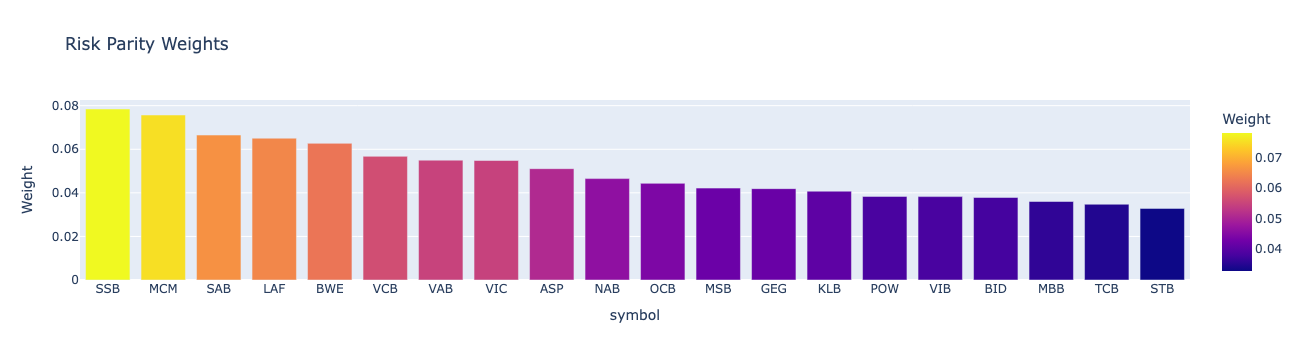

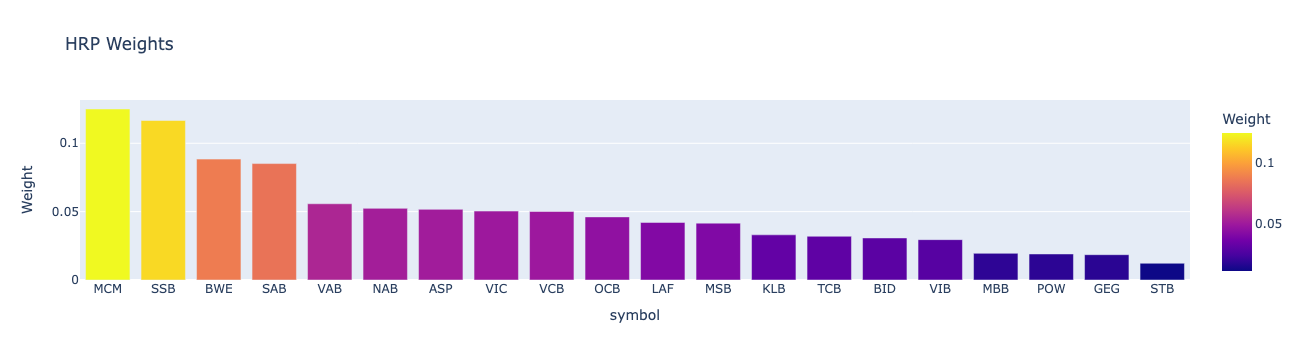

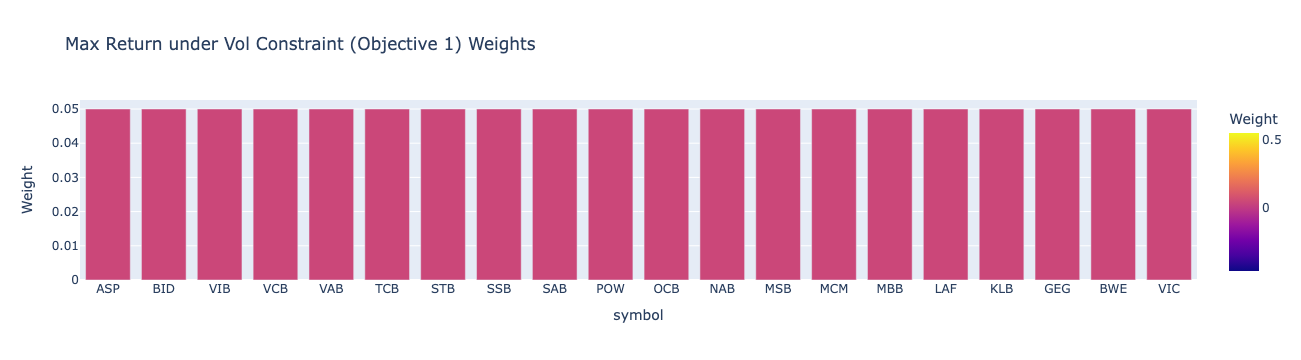

In [5]:
# Cell: Visualize Allocations
display(weight_bar_chart(weights_table["risk_parity"], title="Risk Parity Weights"))
display(weight_bar_chart(weights_table["hrp"], title="HRP Weights"))
display(weight_bar_chart(weights_table["max_ret_under_risk"], title="Max Return under Vol Constraint (Objective 1) Weights"))


In [6]:
# Cell: Risk Contribution & Correlation Review
# 1. Risk Contribution Table for Max Sharpe
max_sharpe_rc = generate_risk_contribution_table(weights_table["max_sharpe"], cov_matrix)
print("--- Risk Contributions (Max Sharpe) ---")
display(max_sharpe_rc)

# 2. Risk Contribution Table for Max Return under Risk Limit
max_ret_risk_rc = generate_risk_contribution_table(weights_table["max_ret_under_risk"], cov_matrix)
print("--- Risk Contributions (Max Return under Risk Limit) ---")
display(max_ret_risk_rc)

# 3. Correlation report for the portfolio assets
corr_report = generate_correlation_report(return_matrix[symbols])
print("\n--- Correlation Report ---")
print(f"Average pairwise correlation: {corr_report['average_pairwise_correlation']:.2f}")
print(f"Max correlation: {corr_report['max_correlation']:.2f} (Pair: {corr_report['max_correlation_pair']})")
if corr_report["high_correlation_alerts"]:
    print("WARNING: High correlation pairs detected:")
    for alert in corr_report["high_correlation_alerts"]:
        print(f"  {alert}")


--- Risk Contributions (Max Sharpe) ---


,symbol,weight,marginal_contribution,total_contribution,risk_contribution_pct
0,ASP,2.146640e-02,0.006390,1.371681e-04,1.119617e+00
1,BID,6.291772e-17,0.010039,6.316534e-19,5.155792e-15
2,BWE,1.392239e-01,0.007931,1.104243e-03,9.013246e+00
3,GEG,1.449681e-16,0.008082,1.171683e-18,9.563718e-15
4,KLB,9.240434e-02,0.013538,1.250985e-03,1.021101e+01
5,LAF,1.628373e-01,0.012498,2.035138e-03,1.661155e+01
6,MBB,9.777992e-17,0.011471,1.121637e-18,9.155218e-15
7,MCM,2.965062e-17,0.003668,1.087541e-19,8.876913e-16
8,MSB,1.122477e-17,0.009117,1.023392e-19,8.353308e-16
9,NAB,4.217429e-02,0.008644,3.645618e-04,2.975690e+00


--- Risk Contributions (Max Return under Risk Limit) ---


,symbol,weight,marginal_contribution,total_contribution,risk_contribution_pct
0,ASP,0.05,0.009712,0.000486,4.472277
1,BID,0.05,0.013860,0.000693,6.382678
2,BWE,0.05,0.007765,0.000388,3.575906
3,GEG,0.05,0.012225,0.000611,5.629768
4,KLB,0.05,0.012914,0.000646,5.946740
5,LAF,0.05,0.006229,0.000311,2.868367
6,MBB,0.05,0.014644,0.000732,6.743722
7,MCM,0.05,0.005984,0.000299,2.755843
8,MSB,0.05,0.012368,0.000618,5.695330
9,NAB,0.05,0.011019,0.000551,5.074077



--- Correlation Report ---
Average pairwise correlation: 0.28
Max correlation: 0.77 (Pair: ('MBB', 'TCB'))
  MBB vs TCB: 0.77


In [7]:
# Cell: Constraint Validation Checks
# Extract sector from clean_daily_ohlcv if available, otherwise mock
sector_series = analysis_df.set_index("symbol")["sector"].drop_duplicates() if "sector" in analysis_df.columns else pd.Series(index=weights_table.index).fillna("Unknown")

# Extract ADTV from clean_daily_ohlcv if available, otherwise mock
adtv_series = analysis_df.groupby("symbol")["value"].mean() if "value" in analysis_df.columns else pd.Series(10_000_000_000, index=weights_table.index)

print("--- Constraint Check Table (Max Sharpe) ---")
display(generate_constraint_check_table(
    weights=weights_table["max_sharpe"],
    covariance=cov_matrix,
    sector_series=sector_series,
    adtv_series=adtv_series,
    nav=1_000_000_000,
    max_vol=0.10,
    max_sector=0.35,
))

print("--- Constraint Check Table (Max Return under Risk Limit) ---")
display(generate_constraint_check_table(
    weights=weights_table["max_ret_under_risk"],
    covariance=cov_matrix,
    sector_series=sector_series,
    adtv_series=adtv_series,
    nav=1_000_000_000,
    max_vol=0.10,
    max_sector=0.35,
))


--- Constraint Check Table (Max Sharpe) ---


,Constraint,Passed,Details
0,Weights Boundary & Sum,True,Sum: 100.00%. Min: 0.00%. Max: 20.38%
1,Annual Volatility <= 10%,False,Portfolio Vol: 19.45%. Max Vol Limit: 10.00%
2,Sector Cap <= 35%,False,Max Sector: Unknown (100.00%). Limit: 35.00%
3,Liquidity ADTV Limit <= 10%,False,Max Liquidity Draw: LAF (143.44%). Limit: 10.00%


--- Constraint Check Table (Max Return under Risk Limit) ---


,Constraint,Passed,Details
0,Weights Boundary & Sum,True,Sum: 100.00%. Min: 5.00%. Max: 5.00%
1,Annual Volatility <= 10%,False,Portfolio Vol: 17.24%. Max Vol Limit: 10.00%
2,Sector Cap <= 35%,False,Max Sector: Unknown (100.00%). Limit: 35.00%
3,Liquidity ADTV Limit <= 10%,False,Max Liquidity Draw: LAF (44.04%). Limit: 10.00%


In [8]:
# Cell: Monte Carlo / Random Portfolio Simulation
print("--- Running Monte Carlo Portfolio Simulation (10,000 portfolios) ---")
n_sim = 10000
portfolios_df = generate_random_portfolios(
    symbols=symbols,
    expected_returns=expected_returns,
    covariance=cov_matrix,
    n_portfolios=n_sim,
    max_weight=0.25,
    min_weight=0.0,
    sector_series=sector_series,
    adtv_series=adtv_series,
    nav=1_000_000_000,
    max_vol=0.10,
    max_sector=0.35,
    max_pct_adtv=0.10,
    risk_free_rate=0.03,
    lambda_penalty=1.0
)

# Count PASS/FAIL
pass_count = (portfolios_df["constraint_status"] == "PASS").sum()
fail_count = (portfolios_df["constraint_status"] == "FAIL").sum()
print(f"Total Portfolios Simulated: {n_sim}")
print(f"  - PASS Constraints: {pass_count} ({pass_count/n_sim:.2%})")
print(f"  - FAIL Constraints: {fail_count} ({fail_count/n_sim:.2%})")

print("\n--- Top 5 Portfolios by Sharpe (PASS only) ---")
display(portfolios_df[portfolios_df["constraint_status"] == "PASS"].sort_values("sharpe_ratio", ascending=False).head(5))

--- Running Monte Carlo Portfolio Simulation (10,000 portfolios) ---
Total Portfolios Simulated: 10000
  - PASS Constraints: 0 (0.00%)
  - FAIL Constraints: 10000 (100.00%)

--- Top 5 Portfolios by Sharpe (PASS only) ---


,portfolio_id,expected_return,portfolio_variance,portfolio_volatility,sharpe_ratio,balanced_score,constraint_status,fail_reason,w_ASP,w_BID,...,w_OCB,w_POW,w_SAB,w_SSB,w_STB,w_TCB,w_VAB,w_VCB,w_VIB,w_VIC


In [9]:
# Cell: Select Optimal Random Portfolios
print("--- Selecting Best Portfolios from Simplex ---")
# Mode 1: Max Return under Vol limit (e.g. 10% vol constraint)
mc_max_ret_w, mc_max_ret_m = select_best_portfolio(
    portfolios_df=portfolios_df,
    symbols=symbols,
    mode="max_return_under_risk",
    max_volatility=0.10
)
print(f"Mode 1 (Max Return s.t. 10% Vol) - Expected Return: {mc_max_ret_m['expected_return']:.2%}, Vol: {mc_max_ret_m['portfolio_volatility']:.2%}")

# Mode 2: Max Sharpe
mc_max_sharpe_w, mc_max_sharpe_m = select_best_portfolio(
    portfolios_df=portfolios_df,
    symbols=symbols,
    mode="max_sharpe"
)
print(f"Mode 2 (Max Sharpe) - Expected Return: {mc_max_sharpe_m['expected_return']:.2%}, Vol: {mc_max_sharpe_m['portfolio_volatility']:.2%}, Sharpe: {mc_max_sharpe_m['sharpe_ratio']:.2f}")

# Mode 3: Min Risk (Acceptable return target 15%)
mc_min_risk_w, mc_min_risk_m = select_best_portfolio(
    portfolios_df=portfolios_df,
    symbols=symbols,
    mode="min_risk",
    target_return=0.15
)
print(f"Mode 3 (Min Risk) - Expected Return: {mc_min_risk_m['expected_return']:.2%}, Vol: {mc_min_risk_m['portfolio_volatility']:.2%}")

# Mode 4: Balanced Score (Expected Return - 1.0 * Variance)
mc_balanced_w, mc_balanced_m = select_best_portfolio(
    portfolios_df=portfolios_df,
    symbols=symbols,
    mode="balanced_score"
)
print(f"Mode 4 (Balanced Score) - Expected Return: {mc_balanced_m['expected_return']:.2%}, Vol: {mc_balanced_m['portfolio_volatility']:.2%}, Score: {mc_balanced_m['balanced_score']:.4f}")

# Append these weights to weights_table
weights_table["mc_max_ret_under_risk"] = mc_max_ret_w
weights_table["mc_max_sharpe"] = mc_max_sharpe_w
weights_table["mc_min_risk"] = mc_min_risk_w
weights_table["mc_balanced_score"] = mc_balanced_w


--- Selecting Best Portfolios from Simplex ---
Mode 1 (Max Return s.t. 10% Vol) - Expected Return: 25.61%, Vol: 20.23%
Mode 2 (Max Sharpe) - Expected Return: 25.61%, Vol: 20.23%, Sharpe: 1.12
Mode 3 (Min Risk) - Expected Return: 15.79%, Vol: 15.48%
Mode 4 (Balanced Score) - Expected Return: 25.61%, Vol: 20.23%, Score: 0.2560


In [ ]:
# Cell: Concentrated Portfolios Selection (3-5 assets)
print("--- Generating Concentrated Portfolios of 3 to 5 Assets ---")
sub_portfolios_df = generate_sub_portfolios(
    symbols=symbols,
    expected_returns=expected_returns,
    covariance=cov_matrix,
    min_size=3,
    max_size=5,
    sector_series=sector_series,
    adtv_series=adtv_series,
    nav=1_000_000_000,
    max_vol=0.10,
    max_sector=0.35,
    max_pct_adtv=0.10,
    risk_free_rate=0.03,
)

print(f"Total sub-portfolios evaluated: {len(sub_portfolios_df)}")
print(f"  - Equal-Weighted combinations: {len(sub_portfolios_df[sub_portfolios_df['type'] == 'Equal-Weight'])} (EQ)")
print(f"  - Optimized combinations: {len(sub_portfolios_df[sub_portfolios_df['type'] == 'Optimized'])} (OPT)")

# Display top 5 concentrated portfolios by Sharpe ratio
top_sub_sharpe = sub_portfolios_df.sort_values("sharpe_ratio", ascending=False).head(5)
print("\n--- Top 5 Concentrated Portfolios (3-5 assets) by Sharpe ---")
display(top_sub_sharpe[["portfolio_name", "size", "tickers", "type", "expected_return", "portfolio_volatility", "sharpe_ratio", "constraint_status"]])

# Extract weights of the best concentrated portfolio
best_sub_row = top_sub_sharpe.iloc[0]
best_sub_name = best_sub_row["portfolio_name"]
best_sub_tickers = best_sub_row["tickers"]
best_sub_type = best_sub_row["type"]

best_sub_w = pd.Series(0.0, index=symbols)
for sym in symbols:
    best_sub_w[sym] = best_sub_row[f"w_{sym}"]

weights_table["mc_best_concentrated_3_5"] = best_sub_w
print(f"\nBest concentrated portfolio selected: {best_sub_name} ({best_sub_type})")
print(f"Tickers included: {best_sub_tickers}")

--- Generating Concentrated Portfolios of 3 to 5 Assets ---


In [ ]:
# Cell: Compare Selected Portfolios
print("--- Portfolio Comparison Table ---")
comp_data = []
port_types = [
    ("Equal-Weight", weights_table["equal_weight"]),
    ("Max Sharpe (Scipy)", weights_table["max_sharpe"]),
    ("Max Return Under Vol (Scipy)", weights_table["max_ret_under_risk"]),
    ("MC Best Return (Risk <= 10%)", weights_table["mc_max_ret_under_risk"]),
    ("MC Best Sharpe", weights_table["mc_max_sharpe"]),
    ("MC Min Risk", weights_table["mc_min_risk"]),
    ("MC Best 3-5 Concentrated", weights_table["mc_best_concentrated_3_5"]),
]

for name, w in port_types:
    summary = generate_portfolio_summary(w, expected_returns, cov_matrix)
    comp_data.append({
        "Portfolio Type": name,
        "Expected Return (Annual)": f"{summary['expected_return']:.2%}",
        "Portfolio Volatility (Annual)": f"{summary['annualized_volatility']:.2%}",
        "Sharpe Ratio": f"{summary['sharpe_ratio']:.2f}",
        "Max Weight": f"{w.max():.2%}",
        "Risk Limit status": "PASS" if summary["annualized_volatility"] <= 0.10 else "FAIL"
    })

display(pd.DataFrame(comp_data))

print("\n--- Optimized Weight Allocations for Each Ticker (%) ---")
display((weights_table * 100).round(2))


In [ ]:
# Cell: Visualize Simulated Random Portfolios
import plotly.graph_objects as go

fig = go.Figure()

# Plot simulated portfolios
fig.add_trace(go.Scatter(
    x=portfolios_df["portfolio_volatility"],
    y=portfolios_df["expected_return"],
    mode="markers",
    marker=dict(
        color=portfolios_df["sharpe_ratio"],
        colorscale="Viridis",
        showscale=True,
        colorbar=dict(title="Sharpe Ratio")
    ),
    text=portfolios_df["fail_reason"],
    hoverinfo="x+y+text",
    name="Simulated Portfolios"
))

# Mark special portfolios
special_ports = [
    ("Equal-Weight", weights_table["equal_weight"], "white", "square"),
    ("Max Sharpe (Scipy)", weights_table["max_sharpe"], "red", "star"),
    ("MC Best Sharpe", weights_table["mc_max_sharpe"], "magenta", "diamond"),
    ("MC Best Return under Risk", weights_table["mc_max_ret_under_risk"], "cyan", "triangle-up"),
    ("MC Min Risk", weights_table["mc_min_risk"], "orange", "circle"),
    ("MC Best 3-5 Concentrated", weights_table["mc_best_concentrated_3_5"], "yellow", "cross")
]

for name, w, color, symbol_shape in special_ports:
    summary = generate_portfolio_summary(w, expected_returns, cov_matrix)
    fig.add_trace(go.Scatter(
        x=[summary["annualized_volatility"]],
        y=[summary["expected_return"]],
        mode="markers+text",
        text=[name],
        textposition="top center",
        marker=dict(color=color, size=15, symbol=symbol_shape, line=dict(color="black", width=2)),
        name=name
))

fig.update_layout(
    title="Monte Carlo Simulation of Simplex Portfolios",
    xaxis_title="Portfolio Volatility (Annualized)",
    yaxis_title="Expected Portfolio Return (Annualized)",
    template="plotly_dark",
    width=1000,
    height=600
)

fig.show()

In [ ]:
# Cell: Save Portfolio Construction Weights
from src.data.loaders import save_parquet

# 1. Save all weights for comparison reference
weights_save_df = weights_table.reset_index(names="symbol")
save_parquet(weights_save_df, "data/signals/portfolio_construction_weights.parquet")
print("Saved portfolio construction weights to data/signals/portfolio_construction_weights.parquet")

# 2. Save the SELECTED optimal portfolio weights for Notebook 15 & 16
# We default to the best concentrated portfolio (3-5 stocks) selected by Monte Carlo
selected_col = "mc_best_concentrated_3_5"
selected_weights = weights_table[selected_col].to_frame("weight").reset_index(names="symbol")
save_parquet(selected_weights, "data/signals/selected_portfolio_weights.parquet")
print(f"Saved selected portfolio weights ({selected_col}) to data/signals/selected_portfolio_weights.parquet")
selected_weights
